# Машинное обучение, ФКН ВШЭ

## Практическое задание 5. Решающие деревья

### Общая информация
Дата выдачи: 29.11.2024

Мягий дедлайн: 23:59 11.12.2024

Жестокий дедлайн: 23:59 13.12.2024

### О задании

Задание состоит из трёх разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево для классификации и сравните его со стандартное имплементацией из sklearn.
3. В третьем разделе вы сделаете решающее дерево для регрессии, в листьях которого линейные модели.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 12.5 баллов.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.


### Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-05-trees-Username.ipynb
* Модуль hw5code.py
* Ссылки на посылки в Яндекс.Контесте для обеих задач

В контест [https://contest.yandex.ru/contest/72492] нужно отправить файл hw5code.py с реализованными функциями и классами.

Username — ваша фамилия и имя на латинице именно в таком порядке

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже:

__Оценка:__

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import Colormap, ListedColormap
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим три простых двумерных датасета сделанных с помощью `make_moons`, `make_circles`, `make_classification` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [ ]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

In [ ]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

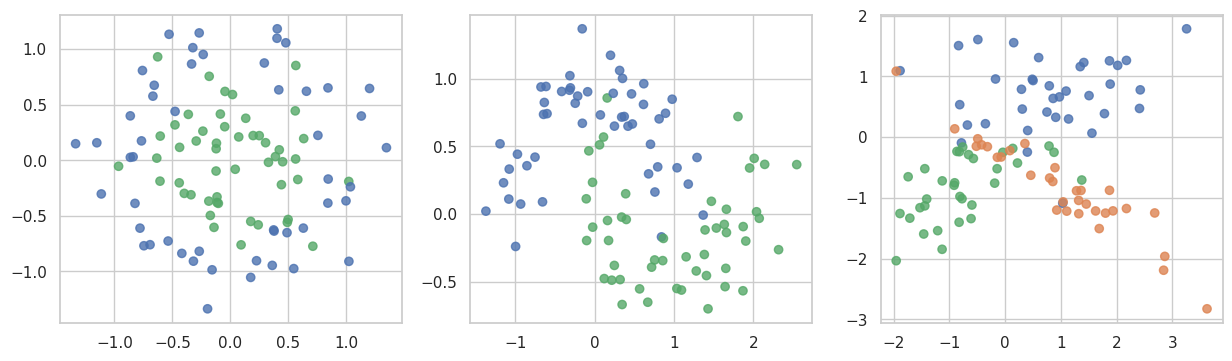

In [ ]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [ ]:
def plot_surface(clf, X, y, ax=None):
    if ax is None:
        ax = plt.gca()
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap_local = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_local, alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_local, alpha=.7,
               edgecolors=np.array(palette)[y], linewidths=2)

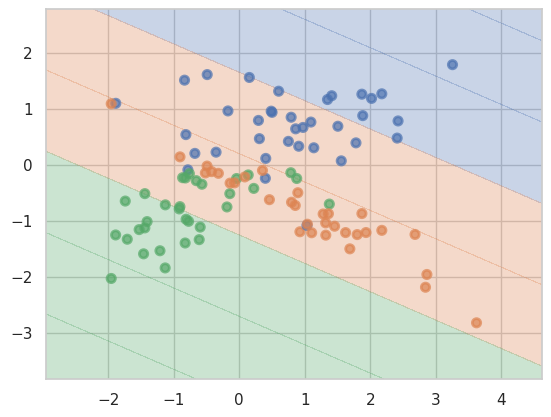

In [ ]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y, None)

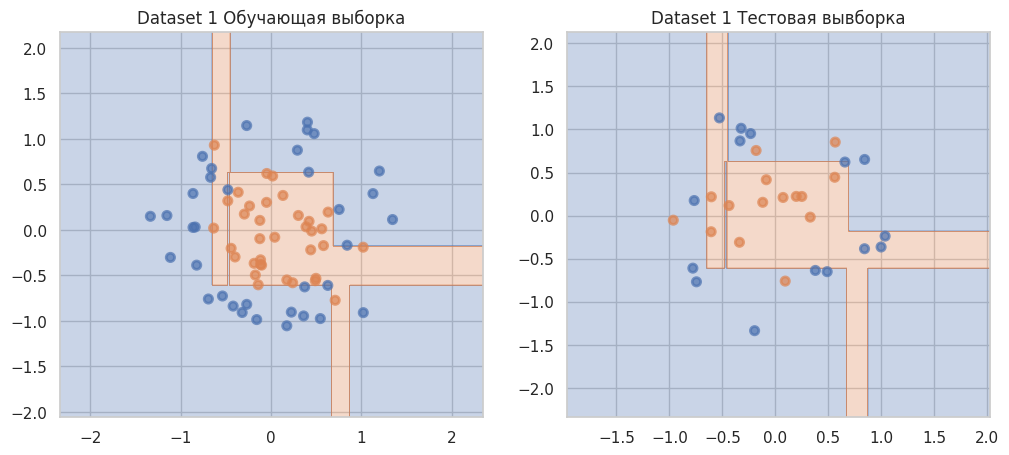

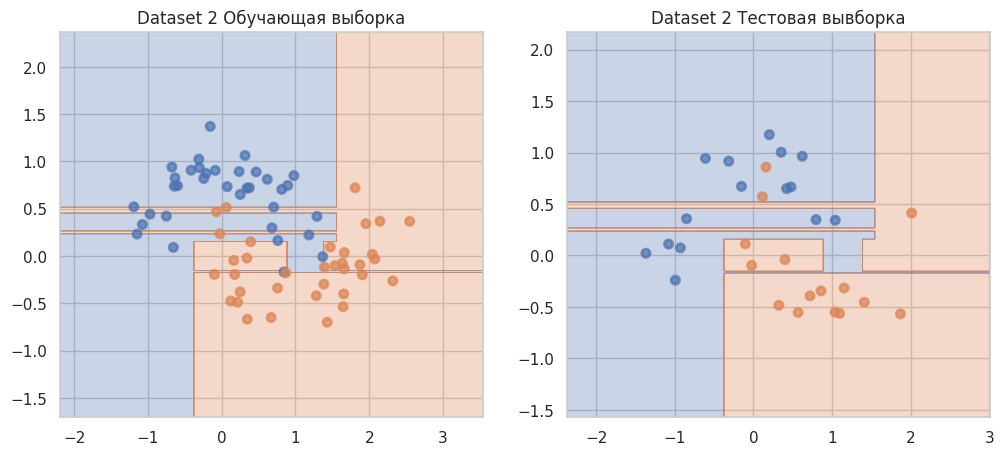

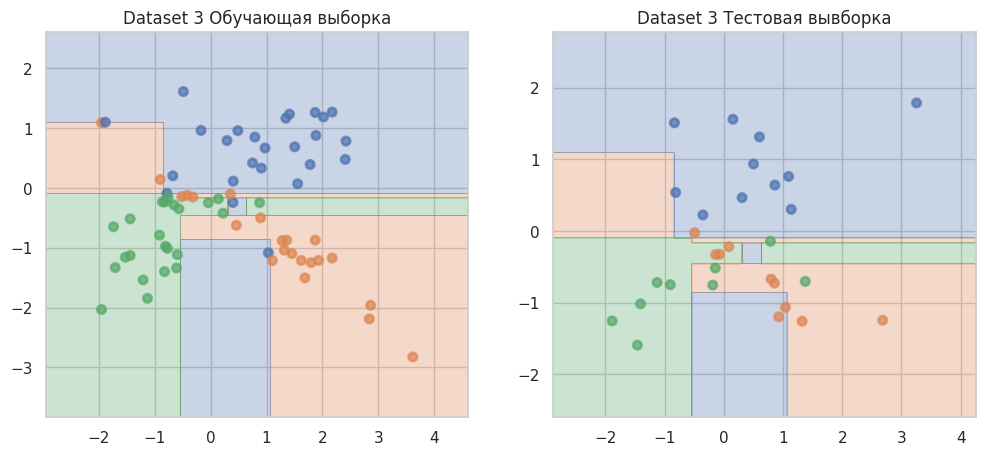

In [ ]:
for i, (X, y) in enumerate(datasets):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_train, y_train)

    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    plot_surface(clf, X_train, y_train, ax=axes[0])
    axes[0].set_title(f'Dataset {i+1} Обучающая выборка')
    plot_surface(clf, X_test, y_test, ax=axes[1])
    axes[1].set_title(f'Dataset {i+1} Тестовая вывборка')
    plt.show()

__Ответ:__

__Задание 2. (1.25 баллов)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки / accuracy. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

__Бонус (0.75 баллов)__

Вместо того, чтобы рисовать  кучу графиков, сделайте интерактивную визуализацию разделяющей гиперплоскости с помощью библиотеки `plotly` (конкретнее, вам пригодится `plotly.graph_objects`): у вас должен получиться виджет с ползунком, по которому можно выбрать параметры `max_depth` и `min_samples_leaf` и посмотреть, как в зависимости от них меняется разделяющая поверхность и прогнозы модели. Если всё сделать аккуратно, получится очень красиво. Помните, что при загрузке в anytask виджеты могут много весить и надо подождать. Если ваш ноутбук не загружается -- попробуйте загрузить сначала с очищенным выводом этой ячейки.

Заранее предупреждаем, что бонус сложный. Полезно будет ознакомиться:
 - https://plotly.com/python/sliders/
 - https://plotly.com/python/dropdowns/
 - https://plotly.com/python/knn-classification/

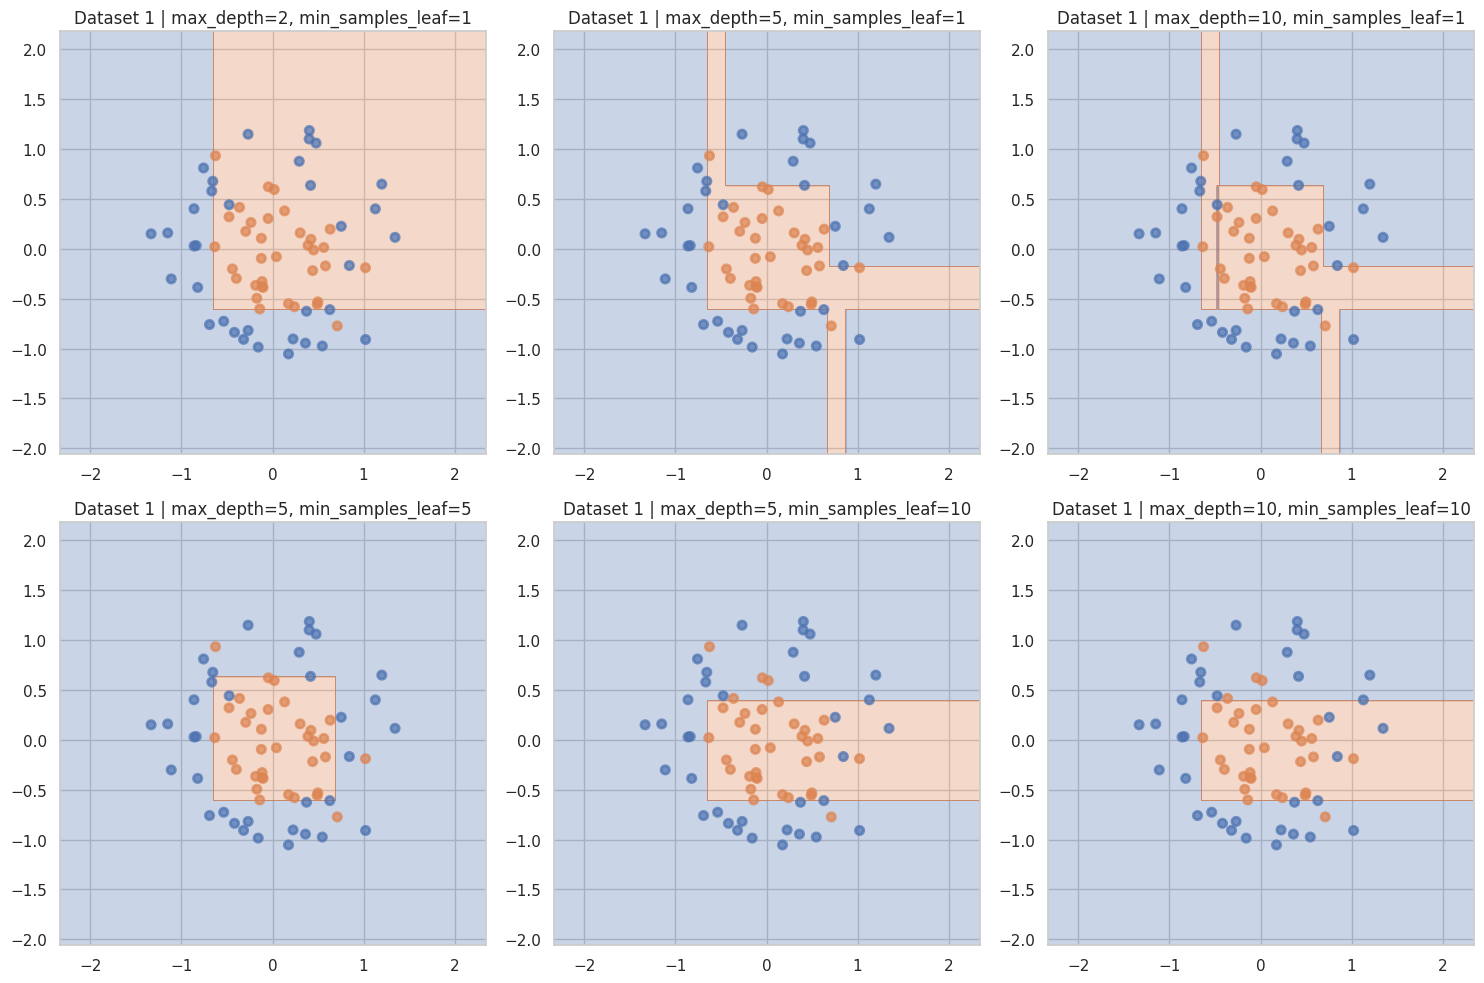

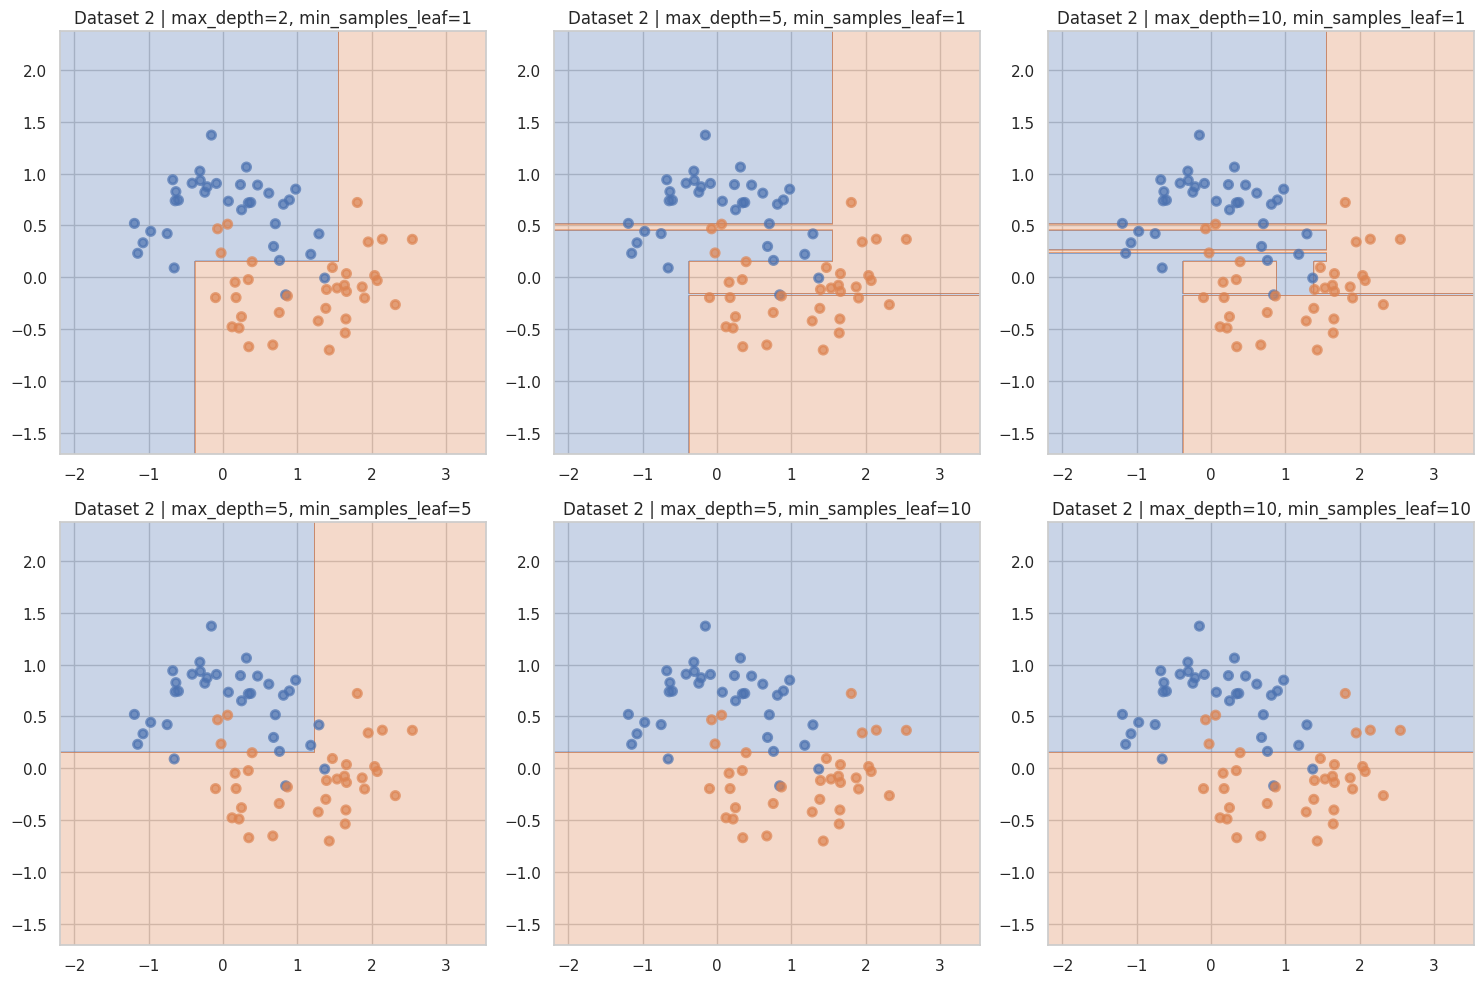

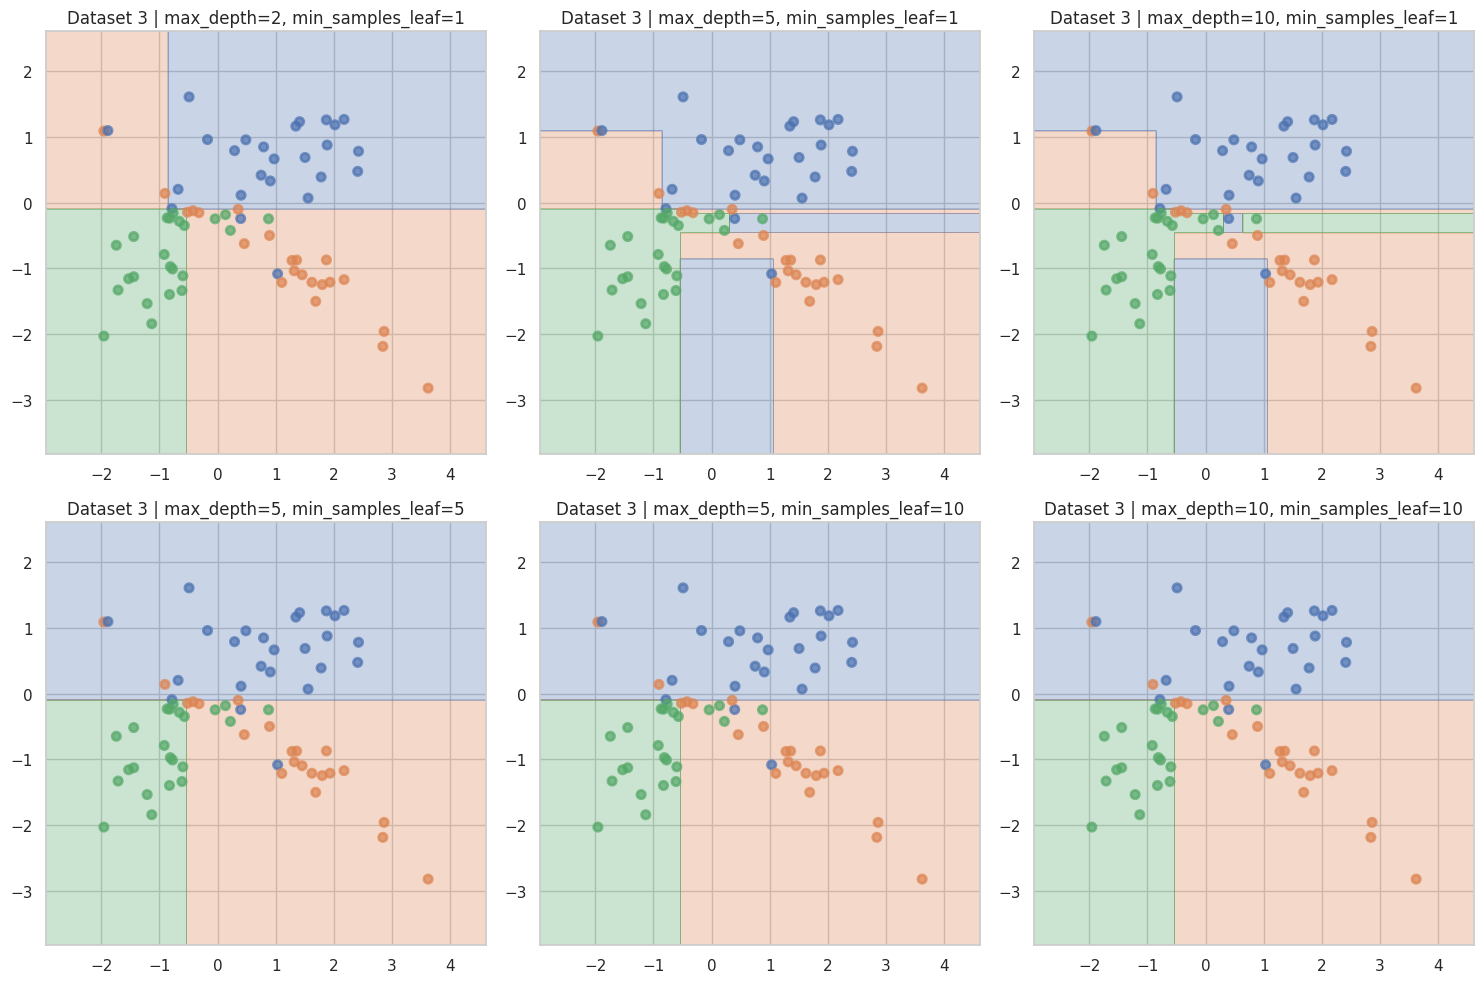

In [ ]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
param_grid = [
    {"max_depth": 2, "min_samples_leaf": 1},
    {"max_depth": 5, "min_samples_leaf": 1},
    {"max_depth": 10, "min_samples_leaf": 1},
    {"max_depth": 5, "min_samples_leaf": 5},
    {"max_depth": 5, "min_samples_leaf": 10},
    {"max_depth": 10, "min_samples_leaf": 10}
]

for i, (X, y) in enumerate(datasets):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.ravel()

    for idx, params in enumerate(param_grid):
        clf = DecisionTreeClassifier(random_state=42, **params)
        clf.fit(X_train, y_train)

        plot_surface(clf, X_train, y_train, ax=axes[idx])
        axes[idx].set_title(f'Dataset {i+1} | max_depth={params["max_depth"]}, min_samples_leaf={params["min_samples_leaf"]}')

    plt.tight_layout()
    plt.show()

__Ответ:__

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw5code.py

$$Q(R) = -\frac {|R_l|}{|R|}H(R_l) -\frac {|R_r|}{|R|}H(R_r)$$,
$R$ — множество объектов, $R_l$ и $R_r$ — объекты, попавшие в левое и правое поддерево
$H(R) = 1-p_1^2-p_0^2$, $p_1$, $p_0$ — доля объектов класса 1 и 0 соответственно.

In [ ]:
import numpy as np
from collections import Counter


def find_best_split(feature_vector, target_vector):
    """
    Под критерием Джини здесь подразумевается следующая функция:
    $$Q(R) = -\frac {|R_l|}{|R|}H(R_l) -\frac {|R_r|}{|R|}H(R_r)$$,
    $R$ — множество объектов, $R_l$ и $R_r$ — объекты, попавшие в левое и правое поддерево,
     $H(R) = 1-p_1^2-p_0^2$, $p_1$, $p_0$ — доля объектов класса 1 и 0 соответственно.

    Указания:
    * Пороги, приводящие к попаданию в одно из поддеревьев пустого множества объектов, не рассматриваются.
    * В качестве порогов, нужно брать среднее двух сосдених (при сортировке) значений признака
    * Поведение функции в случае константного признака может быть любым.
    * При одинаковых приростах Джини нужно выбирать минимальный сплит.
    * За наличие в функции циклов балл будет снижен. Векторизуйте! :)

    :param feature_vector: вещественнозначный вектор значений признака
    :param target_vector: вектор классов объектов,  len(feature_vector) == len(target_vector)

    :return thresholds: отсортированный по возрастанию вектор со всеми возможными порогами, по которым объекты можно
     разделить на две различные подвыборки, или поддерева
    :return ginis: вектор со значениями критерия Джини для каждого из порогов в thresholds len(ginis) == len(thresholds)
    :return threshold_best: оптимальный порог (число)
    :return gini_best: оптимальное значение критерия Джини (число)
    """
    # ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    feature_vector = np.asarray(feature_vector)
    target_vector = np.asarray(target_vector)
    if feature_vector.ndim == 0 or len(feature_vector) <= 1:
        return None, None, None, None

    n = len(feature_vector)
    sorted_idx = np.argsort(feature_vector)
    sorted_features = feature_vector[sorted_idx]
    sorted_targets = target_vector[sorted_idx]

    total_ones = np.sum(sorted_targets)
    total_zeros = n - total_ones

    diff = sorted_features[1:] != sorted_features[:-1]
    candidate_indices = np.where(diff)[0]

    thresholds = (sorted_features[candidate_indices] + sorted_features[candidate_indices + 1]) / 2.0


    cum_ones = np.cumsum(sorted_targets)

    left_sizes = candidate_indices + 1
    left_ones = cum_ones[candidate_indices]
    left_zeros = left_sizes - left_ones

    right_sizes = n - left_sizes
    right_ones = total_ones - left_ones
    right_zeros = total_zeros - left_zeros

    valid = (left_sizes > 0) & (right_sizes > 0)
    if not np.any(valid):
        return None, None, None, None

    p1 = left_ones / left_zeros
    p0 = left_zeros / left_sizes
    gini_left = 1.0 - p1*p1 - p0*p0


    p1 = right_ones / right_zeros
    p0 = right_zeros / right_sizes
    gini_right =  1.0 - p1*p1 - p0*p0

    ginis = - (left_sizes / n) * gini_left - (right_sizes / n) * gini_right

    best_idx = np.argmin(ginis)
    threshold_best = thresholds[best_idx]
    gini_best = ginis[best_idx]

    return thresholds, ginis, threshold_best, gini_best

__Задание 4. (0.5 балла)__

Загрузите таблицу [students.csv](https://github.com/esokolov/ml-course-hse/blob/master/2022-fall/homeworks-practice/homework-practice-05-trees/students.csv) (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

In [ ]:
df = pd.read_csv('students.csv')
df.sample()

,STG,SCG,STR,LPR,PEG,UNS
201,0.64,0.09,0.33,0.65,0.5,1


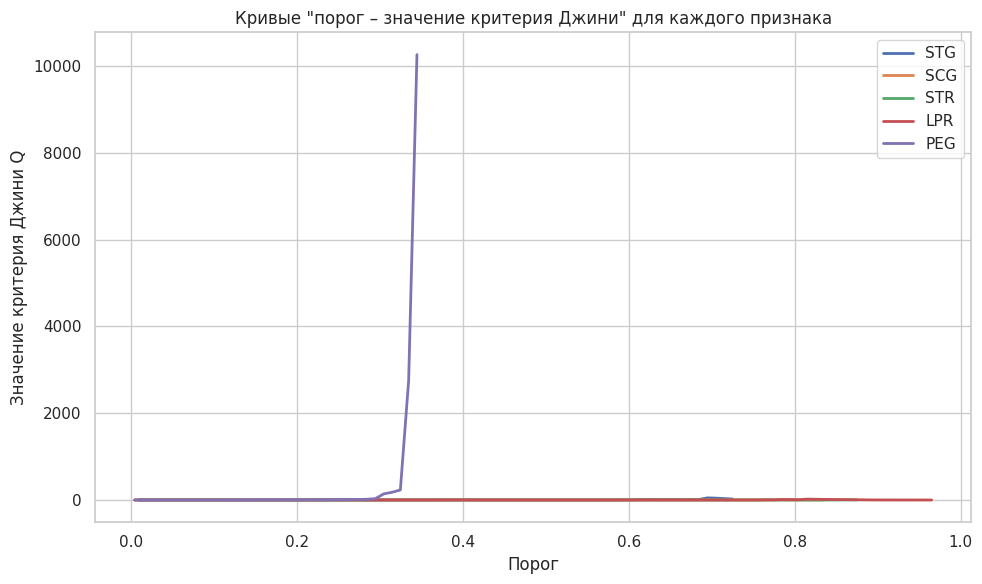

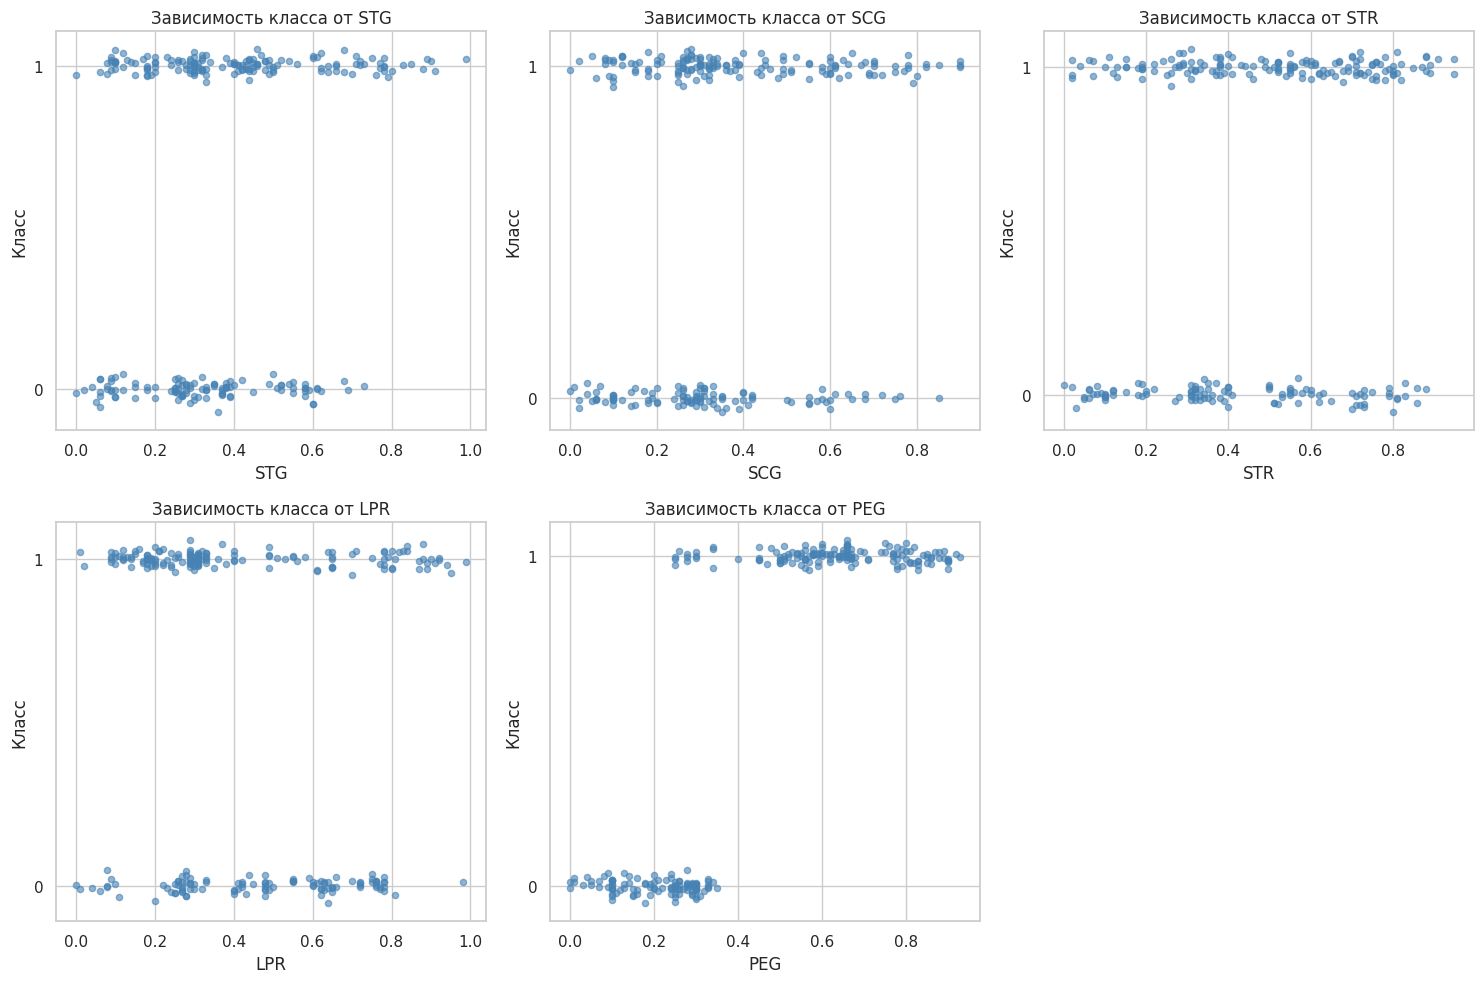

In [ ]:

df = pd.read_csv('students.csv')
X = df.iloc[:, :5].values
y = df.iloc[:, -1].values

feature_names = df.columns[:5].tolist()


plt.figure(figsize=(10, 6))
for i in range(5):
    thresholds, ginis, _, _ = find_best_split(X[:, i], y)
    if len(thresholds) > 0:
        plt.plot(thresholds, ginis, label=feature_names[i], linewidth=2)
    else:
        print(f"Признак '{feature_names[i]}' константный – нет порогов.")
plt.xlabel('Порог')
plt.ylabel('Значение критерия Джини Q')
plt.title('Кривые "порог – значение критерия Джини" для каждого признака')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for i in range(5):
    jitter = np.random.normal(0, 0.02, size=len(y))
    axes[i].scatter(X[:, i], y + jitter, alpha=0.6, s=20, c='steelblue')
    axes[i].set_xlabel(feature_names[i])
    axes[i].set_ylabel('Класс')
    axes[i].set_yticks([0, 1])
    axes[i].set_title(f'Зависимость класса от {feature_names[i]}')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:**

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw5code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в [лекции](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/lecture-notes/lecture07-trees.pdf) в разделе «Построение дерева». Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

In [ ]:
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")

        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node):
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            categories_map = {}

            if feature_type == "real":
                feature_vector = sub_X[:, feature]
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {}
                for key, current_count in counts.items():
                    current_click = clicks.get(key, 1e-10)
                    ratio[key] = current_count / current_click
                sorted_categories = [cat for cat, _ in sorted(ratio.items(), key=lambda x: x[1])]
                categories_map = {cat: i for i, cat in enumerate(sorted_categories)}
                feature_vector = np.array([categories_map[x] for x in sub_X[:, feature]])
            else:
                raise ValueError

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)
            if threshold is None or gini is None:
                continue

            if gini_best is None or gini < gini_best:
                feature_best = feature
                gini_best = gini
                split = feature_vector < threshold

                if feature_type == "real":
                    threshold_best = threshold
                elif feature_type == "categorical":
                    threshold_best = [cat for cat, val in categories_map.items() if val < threshold]
                else:
                    raise ValueError

        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"
        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        elif self._feature_types[feature_best] == "categorical":
            node["categories_split"] = threshold_best
        else:
            raise ValueError

        node["left_child"], node["right_child"] = {}, {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"])
        self._fit_node(sub_X[~split], sub_y[~split], node["right_child"])

    def _predict_node(self, x, node):
        # ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
        if node["type"] == "terminal":
            return node["class"]

        feature = node["feature_split"]
        feature_type = self._feature_types[feature]

        if feature_type == "real":
            if x[feature] < node["threshold"]:
                return self._predict_node(x, node["left_child"])
            else:
                return self._predict_node(x, node["right_child"])

        elif feature_type == "categorical":
            if x[feature] in node["categories_split"]:
                return self._predict_node(x, node["left_child"])
            else:
                return self._predict_node(x, node["right_child"])
        else:
            raise ValueError

    def fit(self, X, y):
        self._fit_node(X, y, self._tree)

    def predict(self, X):
        predicted = []
        for x in X:
            predicted.append(self._predict_node(x, self._tree))
        return np.array(predicted)

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [ ]:
!pip install ucimlrepo

In [ ]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo
mushroom = fetch_ucirepo(id=73)

X = mushroom.data.features
y = mushroom.data.targets

X_df = pd.DataFrame(X)
y_df = pd.DataFrame(y)

data = pd.concat([X_df, y_df], axis=1)


for col in data.columns:
    data[col] = LabelEncoder().fit_transform(data[col])


X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)


feature_types = ['categorical'] * X.shape[1]

tree = DecisionTree(feature_types=feature_types)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy на тестовой выборке: {acc:.4f}")

Accuracy на тестовой выборке: 0.9806


__Задание 8. (1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (https://github.com/esokolov/ml-course-hse/blob/master/2024-fall/homework-practice/homework-practice-05-trees/tic-tac-toe-endgame.csv).

In [ ]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=2, min_samples_leaf=1):
        if np.any([ft not in ("real", "categorical") for ft in feature_types]):
            raise ValueError("Unknown feature type")
        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node, depth=0):
        # Условия останова
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        # Ограничение по глубине
        if self._max_depth is not None and depth >= self._max_depth:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        # Минимальное количество объектов для разбиения
        if sub_X.shape[0] < self._min_samples_split:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        best_gini = None
        best_feature = None
        best_threshold = None
        best_split = None
        best_cat_map = None

        for feature in range(sub_X.shape[1]):
            ftype = self._feature_types[feature]
            col = sub_X[:, feature]

            if ftype == "real":
                feat_vec = col
                cat_map = None
            else:  # categorical
                counts = Counter(col)
                pos_counts = Counter(col[sub_y == 1])
                ratio = {}
                for k in counts:
                    pos = pos_counts.get(k, 1e-10)
                    ratio[k] = counts[k] / pos
                sorted_cats = [c for c, _ in sorted(ratio.items(), key=lambda x: x[1])]
                cat_map = {c: i for i, c in enumerate(sorted_cats)}
                feat_vec = np.array([cat_map[x] for x in col])

            _, _, thresh, gini = find_best_split(feat_vec, sub_y)
            if thresh is None:
                continue

            # Проверка min_samples_leaf на левой и правой части
            split_mask = feat_vec < thresh
            if self._min_samples_leaf is not None:
                left_size = np.sum(split_mask)
                right_size = len(feat_vec) - left_size
                if left_size < self._min_samples_leaf or right_size < self._min_samples_leaf:
                    continue

            if best_gini is None or gini < best_gini:
                best_gini = gini
                best_feature = feature
                best_threshold = thresh
                best_split = split_mask
                if ftype == "categorical":
                    best_cat_map = cat_map

        if best_feature is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"
        node["feature_split"] = best_feature
        if self._feature_types[best_feature] == "real":
            node["threshold"] = best_threshold
        else:
            left_cats = [c for c, val in best_cat_map.items() if val < best_threshold]
            node["categories_split"] = left_cats

        node["left_child"] = {}
        node["right_child"] = {}
        self._fit_node(sub_X[best_split], sub_y[best_split], node["left_child"], depth+1)
        self._fit_node(sub_X[~best_split], sub_y[~best_split], node["right_child"], depth+1)

    def _predict_node(self, x, node):
        if node["type"] == "terminal":
            return node["class"]
        feat = node["feature_split"]
        if self._feature_types[feat] == "real":
            if x[feat] < node["threshold"]:
                return self._predict_node(x, node["left_child"])
            else:
                return self._predict_node(x, node["right_child"])
        else:
            if x[feat] in node["categories_split"]:
                return self._predict_node(x, node["left_child"])
            else:
                return self._predict_node(x, node["right_child"])

    def fit(self, X, y):
        self._fit_node(X, y, self._tree)

    def predict(self, X):
        return np.array([self._predict_node(x, self._tree) for x in X])

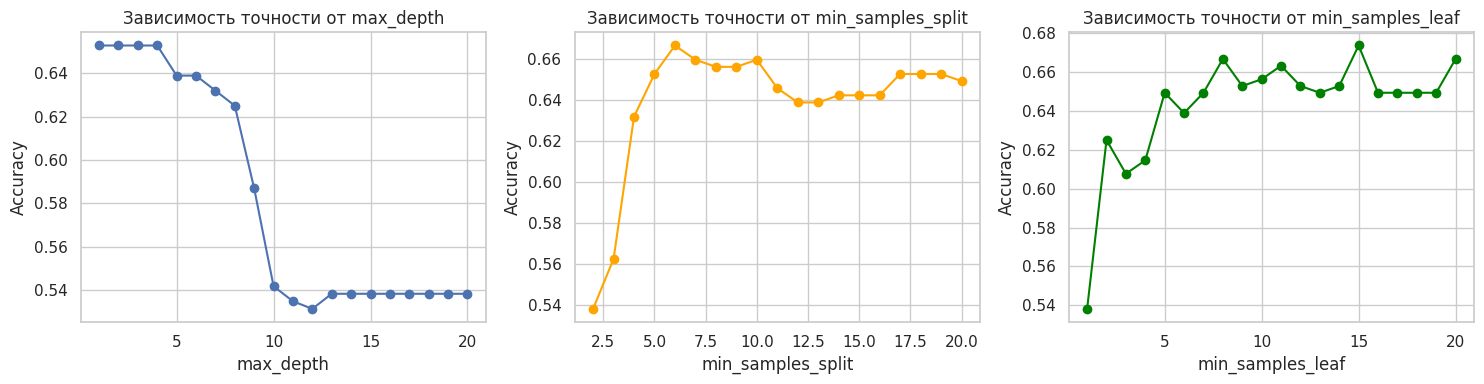

Максимальная accuracy (max_depth=1): 0.6528
Максимальная accuracy (min_samples_split=6): 0.6667
Максимальная accuracy (min_samples_leaf=15): 0.6736


In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/esokolov/ml-course-hse/master/2024-fall/homework-practice/homework-practice-05-trees/tic-tac-toe-endgame.csv")

y = data.iloc[:, -1].values
X = data.iloc[:, :-1].values

le = LabelEncoder()
X_enc = np.zeros_like(X, dtype=int)
for i in range(X.shape[1]):
    X_enc[:, i] = le.fit_transform(X[:, i])

y_enc = LabelEncoder().fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y_enc, test_size=0.3, random_state=42, stratify=y_enc
)

feature_types = ["categorical"] * X_train.shape[1]

def evaluate_tree(max_depth=None, min_samples_split=2, min_samples_leaf=1):
    tree = DecisionTree(feature_types,
                        max_depth=max_depth,
                        min_samples_split=min_samples_split,
                        min_samples_leaf=min_samples_leaf)
    tree.fit(X_train, y_train)
    preds = tree.predict(X_test)
    return accuracy_score(y_test, preds)


plt.figure(figsize=(15, 4))

depth_vals = list(range(1, 21))
acc_depth = []
for d in depth_vals:
    acc_depth.append(evaluate_tree(max_depth=d, min_samples_split=2, min_samples_leaf=1))

plt.subplot(1, 3, 1)
plt.plot(depth_vals, acc_depth, marker='o')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Зависимость точности от max_depth")
plt.grid(True)

split_vals = list(range(2, 21))
acc_split = []
for s in split_vals:
    acc_split.append(evaluate_tree(max_depth=None, min_samples_split=s, min_samples_leaf=1))

plt.subplot(1, 3, 2)
plt.plot(split_vals, acc_split, marker='o', color='orange')
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Зависимость точности от min_samples_split")
plt.grid(True)


leaf_vals = list(range(1, 21))
acc_leaf = []
for l in leaf_vals:
    acc_leaf.append(evaluate_tree(max_depth=None, min_samples_split=2, min_samples_leaf=l))

plt.subplot(1, 3, 3)
plt.plot(leaf_vals, acc_leaf, marker='o', color='green')
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Зависимость точности от min_samples_leaf")
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Максимальная accuracy (max_depth={depth_vals[np.argmax(acc_depth)]}): {max(acc_depth):.4f}")
print(f"Максимальная accuracy (min_samples_split={split_vals[np.argmax(acc_split)]}): {max(acc_split):.4f}")
print(f"Максимальная accuracy (min_samples_leaf={leaf_vals[np.argmax(acc_leaf)]}): {max(acc_leaf):.4f}")